# Generación de Puntos Ideales (Ideal Points)
---

Este notebook implementa el cálculo de puntos ideales usando Item Response Theory (IRT) para analizar el comportamiento de votación de los legisladores

## Puntos Ideales

Representan la posición ideológica de cada legislador en un espectro político unidimensional, calculados a partir de sus patrones de votación

## Algoritmo

Utilizaremos una implementación basada en IRT (Item Response Theory) con `pymc` o una implementación manual

In [2]:
import pandas as pd
import numpy as np
import os
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA  # Para cálculo de puntos ideales usaremos PCA como aproximación
from sklearn.preprocessing import StandardScaler

In [3]:
# Definir rutas de trabajo
carpeta_legislativas = 'legislativas/'
carpeta_sesiones = os.path.join(carpeta_legislativas, "diputados", "01_scraping", "sesiones")
carpeta_idps = os.path.join(carpeta_legislativas, "diputados", "02_puntos ideales", "idps")

# Crear carpeta para puntos ideales
os.makedirs(carpeta_idps, exist_ok=True)

In [4]:
# Cargar datos de sesiones
ruta_sesiones = os.path.join(carpeta_sesiones, "sesiones_dt.csv.gz")
sesiones = pd.read_csv(ruta_sesiones, compression='gzip')

sesiones.head()

,legislador,bloque,provincia,voto,id_votacion,yr,legislador_id,bloque_id,provincia_id
0,"BESANA, GABRIELA",Pro,Buenos Aires,AFIRMATIVO,4528,2022,50,39,1
1,"SALVADOR, SEBASTIAN NICOLAS",Ucr,Buenos Aires,NEGATIVO,4589,2022,316,49,1
2,"SALVADOR, SEBASTIAN NICOLAS",Ucr,Buenos Aires,AFIRMATIVO,4649,2022,316,49,1
3,"SALVADOR, SEBASTIAN NICOLAS",Ucr,Buenos Aires,AFIRMATIVO,4594,2022,316,49,1
4,"SALVADOR, SEBASTIAN NICOLAS",Ucr,Buenos Aires,AFIRMATIVO,4828,2023,316,49,1


In [5]:
# Obtener años únicos
anios = sorted(sesiones['yr'].dropna().unique().astype(int).tolist())
anios

[2022, 2023, 2024, 2025]

In [6]:
# Filtrar solo votos válidos
votos_validos = ['AUSENTE', 'AFIRMATIVO', 'NEGATIVO', 'ABSTENCION']
sesiones = sesiones[sesiones['voto'].isin(votos_validos)].copy()

# Ordenar por año e id_votacion
sesiones = sesiones.sort_values(['yr', 'id_votacion']).reset_index(drop=True)
sesiones['id'] = range(1, len(sesiones) + 1)

print(sesiones['voto'].value_counts())

voto
AFIRMATIVO    58882
NEGATIVO      26894
AUSENTE       13198
ABSTENCION     2098
Name: count, dtype: int64


## Función para Calcular Puntos Ideales por Año

**Metodología**
1. **Crear matriz de votación**: Legisladores (filas) × Votaciones (columnas)
2. **Codificar votos**: AFIRMATIVO=1, NEGATIVO=-1, AUSENTE/ABSTENCION=0
3. **Aplicar PCA**: Primera componente principal = punto ideal
4. **Normalizar**: Escalar los valores entre -1 y 1

In [7]:
def calcular_puntos_ideales_año(votos_anio, anio):
    """
    Calcula puntos ideales para un año específico.
    Aproximación del algoritmo pscl::ideal() usando PCA.
    
    Args:
        votos_anio: DataFrame con votaciones del año
        anio: Año a procesar
    
    Returns:
        DataFrame con legislador, punto ideal y año
    """
    print(f"Procesando año {anio}...")
    
    # Obtener legisladores y votaciones únicas
    legisladores = votos_anio['legislador'].unique()
    votaciones = votos_anio['id_votacion'].unique()
    
    n_legis = len(legisladores)
    n_votos = len(votaciones)
    
    print(f"  - Legisladores: {n_legis}")
    print(f"  - Votaciones: {n_votos}")
    
    # Crear matriz: legisladores × votaciones
    matriz_votos = np.zeros((n_legis, n_votos))
    
    # Mapear votos a valores numéricos
    mapa_votos = {
        'AFIRMATIVO': 1,
        'NEGATIVO': -1,
        'AUSENTE': 0,
        'ABSTENCION': 0
    }
    
    # Llenar la matriz
    leg_to_idx = {leg: i for i, leg in enumerate(legisladores)}
    vot_to_idx = {vot: i for i, vot in enumerate(votaciones)}
    
    for _, row in votos_anio.iterrows():
        i = leg_to_idx[row['legislador']]
        j = vot_to_idx[row['id_votacion']]
        matriz_votos[i, j] = mapa_votos.get(row['voto'], 0)
    
    # Eliminar legisladores que no votaron en nada
    votos_totales = np.sum(np.abs(matriz_votos), axis=1)
    mask_activos = votos_totales > 0
    
    matriz_votos = matriz_votos[mask_activos]
    legisladores_activos = legisladores[mask_activos]
    
    print(f"  - Legisladores activos: {len(legisladores_activos)}")
    
    # Aplicar PCA para obtener puntos ideales
    # Primera componente = posición ideológica
    scaler = StandardScaler()
    matriz_scaled = scaler.fit_transform(matriz_votos)
    
    pca = PCA(n_components=1)
    puntos_ideales = pca.fit_transform(matriz_scaled)
    
    # Normalizar a escala [-1, 1]
    idps = puntos_ideales.flatten()
    idps = (idps - idps.min()) / (idps.max() - idps.min()) * 2 - 1
    
    # Crear DataFrame de resultados
    resultado = pd.DataFrame({
        'nombre': legisladores_activos,
        'idp': idps,
        'anio': anio
    })
    
    varianza_explicada = pca.explained_variance_ratio_[0]
    print(f"Varianza explicada: {varianza_explicada:.2%}")
    
    return resultado

In [8]:
# Calcular puntos ideales para todos los años
idps_list = []

for anio in tqdm(anios, desc="Procesando años"):
    votos_anio = sesiones[sesiones['yr'] == anio]
    idps_anio = calcular_puntos_ideales_año(votos_anio, anio)
    idps_list.append(idps_anio)

# Consolidar todos los puntos ideales
idps = pd.concat(idps_list, ignore_index=True)
idps.head(10)

Procesando años:   0%|          | 0/4 [00:00<?, ?it/s]

Procesando año 2022...
  - Legisladores: 259
  - Votaciones: 79


Procesando años:  25%|██▌       | 1/4 [00:00<00:02,  1.05it/s]

  - Legisladores activos: 258
Varianza explicada: 39.97%
Procesando año 2023...
  - Legisladores: 265
  - Votaciones: 55


Procesando años:  50%|█████     | 2/4 [00:01<00:01,  1.32it/s]

...

Procesando años:  75%|███████▌  | 3/4 [00:03<00:01,  1.34s/it]

  - Legisladores activos: 261
Varianza explicada: 61.86%
Procesando año 2025...
  - Legisladores: 262
  - Votaciones: 81


Procesando años: 100%|██████████| 4/4 [00:04<00:00,  1.13s/it]

  - Legisladores activos: 262
Varianza explicada: 71.61%


,nombre,idp,anio
0,"CAMAÑO, GRACIELA",-0.009399,2022
1,"RODRIGUEZ, ALEJANDRO ""TOPO""",-0.350288,2022
2,"RANDAZZO, FLORENCIO",0.224501,2022
3,"DEL CAÑO, NICOLAS",-0.070448,2022
4,"VARGAS MATYI, BRENDA",-0.983681,2022
5,"GUTIERREZ, RAMIRO",-0.817921,2022
6,"GOLLAN, DANIEL",-0.991841,2022
7,"GROSSO, LEONARDO",-0.829595,2022
8,"APARICIO, ALICIA N.",-0.724506,2022
9,"LAMPREABE, FLORENCIA",-0.909565,2022


In [9]:
# Guardar puntos ideales
ruta_idps = os.path.join(carpeta_idps, "idps.csv")
idps.to_csv(ruta_idps, index=False)

## Calcular Distancias entre Puntos Ideales

In [10]:
# Calcular distancias para cada año
distancias_list = []

for anio in tqdm(anios, desc="Calculando distancias"):
    idps_anio = idps[idps['anio'] == anio].copy()
    
    # Crear todas las combinaciones posibles
    from itertools import combinations
    
    distancias_anio = []
    
    for i, row1 in idps_anio.iterrows():
        for j, row2 in idps_anio.iterrows():
            if i < j:  # Evitar duplicados y auto-distancias
                dist = abs(row1['idp'] - row2['idp'])
                distancias_anio.append({
                    'nombre1': row1['nombre'],
                    'nombre2': row2['nombre'],
                    'idp_desde': row1['idp'],
                    'idp_hasta': row2['idp'],
                    'distancia': dist,
                    'anio': anio
                })
    
    distancias_list.extend(distancias_anio)

# Consolidar distancias
distancias = pd.DataFrame(distancias_list)

# Filtrar distancias > 0
distancias = distancias[distancias['distancia'] > 0]
distancias.head()

Calculando distancias: 100%|██████████| 4/4 [00:10<00:00,  2.67s/it]


,nombre1,nombre2,idp_desde,idp_hasta,distancia,anio
0,"CAMAÑO, GRACIELA","RODRIGUEZ, ALEJANDRO ""TOPO""",-0.009399,-0.350288,0.340889,2022
1,"CAMAÑO, GRACIELA","RANDAZZO, FLORENCIO",-0.009399,0.224501,0.233899,2022
2,"CAMAÑO, GRACIELA","DEL CAÑO, NICOLAS",-0.009399,-0.070448,0.061049,2022
3,"CAMAÑO, GRACIELA","VARGAS MATYI, BRENDA",-0.009399,-0.983681,0.974283,2022
4,"CAMAÑO, GRACIELA","GUTIERREZ, RAMIRO",-0.009399,-0.817921,0.808522,2022


In [11]:
# Guardar distancias
ruta_distancias = os.path.join(carpeta_idps, "distancias_idps.csv.gz")
distancias.to_csv(ruta_distancias, index=False, compression='gzip')

## Visualizaciones

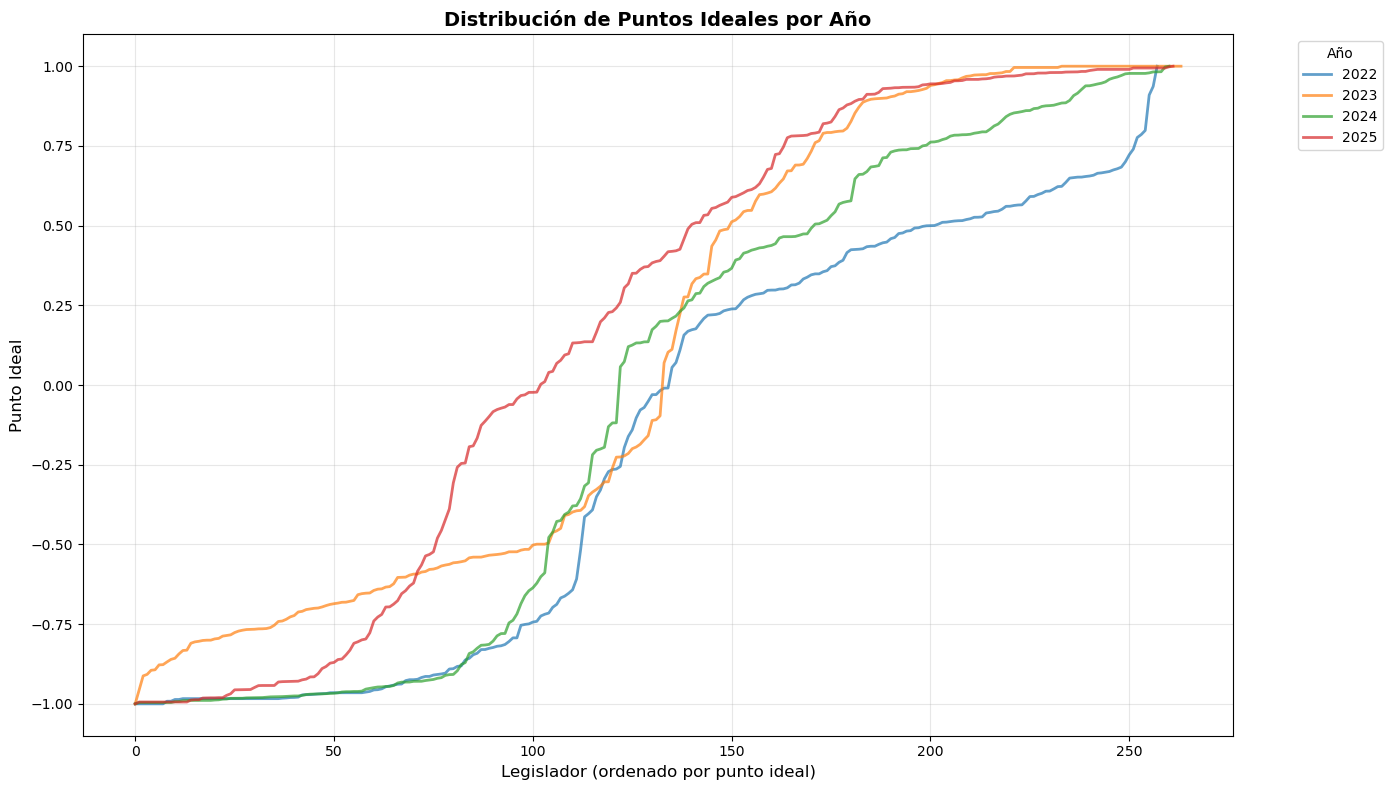

In [12]:
# Visualizar puntos ideales por año
fig, ax = plt.subplots(figsize=(14, 8))

for anio in anios:
    idps_anio = idps[idps['anio'] == anio].sort_values('idp').reset_index(drop=True)
    idps_anio['i'] = range(len(idps_anio))
    ax.plot(idps_anio['i'], idps_anio['idp'], label=str(anio), linewidth=2, alpha=0.7)

ax.set_xlabel('Legislador (ordenado por punto ideal)', fontsize=12)
ax.set_ylabel('Punto Ideal', fontsize=12)
ax.set_title('Distribución de Puntos Ideales por Año', fontsize=14, fontweight='bold')
ax.legend(title='Año', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

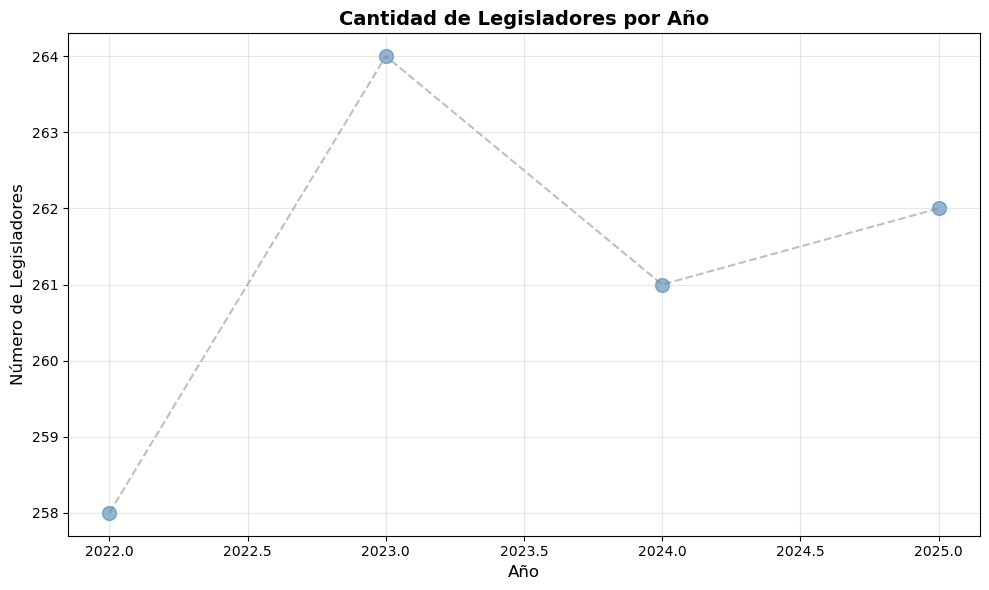

In [13]:
# Visualizar cantidad de legisladores por año
conteo_anual = idps.groupby('anio').size().reset_index(name='N')

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(conteo_anual['anio'], conteo_anual['N'], s=100, alpha=0.6, color='steelblue')
ax.plot(conteo_anual['anio'], conteo_anual['N'], linestyle='--', alpha=0.5, color='gray')

ax.set_xlabel('Año', fontsize=12)
ax.set_ylabel('Número de Legisladores', fontsize=12)
ax.set_title('Cantidad de Legisladores por Año', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Guardar Info Adicional: Legisladores con Bloque y Provincia

In [14]:
# Obtener el último bloque y provincia de cada legislador por año
# (equivalente a last() en data.table R)
legisladores_info = sesiones.sort_values(['yr', 'id_votacion']).groupby(['legislador', 'yr']).last()[
    ['bloque', 'provincia']
].reset_index()

legisladores_info.head()

,legislador,yr,bloque,provincia
0,"ACEVEDO, SERGIO EDGARDO",2024,Por Santa Cruz,Santa Cruz
1,"ACEVEDO, SERGIO EDGARDO",2025,Por Santa Cruz,Santa Cruz
2,"AGOST CARREÑO, OSCAR",2023,Pro,Córdoba
3,"AGOST CARREÑO, OSCAR",2024,Encuentro Federal,Córdoba
4,"AGOST CARREÑO, OSCAR",2025,Encuentro Federal,Córdoba


In [15]:
# Guardar legisladores con bloque y provincia
ruta_legisladores = os.path.join(carpeta_idps, "legisladores_bloque_provincia.csv")
legisladores_info.to_csv(ruta_legisladores, index=False)